<a href="https://colab.research.google.com/github/Pratyush0206/Parle/blob/main/parle_transformer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Parle: French→English Transformer from Scratch

An encoder–decoder Transformer for French→English translation on Multi30k, written in PyTorch without `nn.Transformer` or `nn.MultiheadAttention`.

- 2 encoder + 2 decoder layers, d_model 128, 4 attention heads, feed-forward 128 → 512 → 128
- Separate 4,000-piece BPE vocabularies (SentencePiece) for French and English
- Greedy and beam-search decoding, evaluated with corpus-level SacreBLEU on the 1,000-sentence test set

Run the cells from top to bottom.

## Data

In [1]:
import importlib.util
import subprocess
import sys
if importlib.util.find_spec('sentencepiece') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'sentencepiece==0.2.1'])

import os
import io
import gzip
import hashlib
import urllib.request
from pathlib import Path
import torch
import sentencepiece as spm
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

torch.manual_seed(42)
PAD_ID, UNK_ID, BOS_ID, EOS_ID = 0, 1, 2, 3
DATA_DIR = Path(os.environ.get('NNDL_DATA_ROOT', 'data')) / 'multi30k_en_fr'
DATA_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# Download the six text files from a fixed Multi30k revision; reuse cached files.
REVISION = 'a3d2e0d26b56f3846f66a952536ffed4e401d05a'
BASE_URL = f'https://raw.githubusercontent.com/multi30k/dataset/{REVISION}/data/task1/raw'
SHA256 = {
    "train.en.gz": "d79cfa999dd4c51d2cb42499b6796d5a882c3a8a961923c25a898c90f8bbd56f",
    "train.fr.gz": "622e75069e9f4c577425c4f277116ce66e63a2401c0a2312d90073cb12379a3c",
    "val.en.gz": "14f7d25ddd868909a9213e361768460edcacdd6ab9d1e77b92560dc10c10dc28",
    "val.fr.gz": "ca3106f1a72390591d25f6c45cb4cd39dec4cd3f123e099748a3ce5256c160e9",
    "test_2016_flickr.en.gz": "611d361c6334bc7246101d48097c13cf5c4413c5befc793cc629934359d532d9",
    "test_2016_flickr.fr.gz": "6d326e188d259fb1d04ac19eae3af956559b3a0b93d7635e56c90987c40c8b90"
}

def read_lines(filename):
    path = DATA_DIR / filename
    if not path.exists():
        with urllib.request.urlopen(f'{BASE_URL}/{filename}', timeout=60) as response:
            payload = response.read()
        if hashlib.sha256(payload).hexdigest() != SHA256[filename]:
            raise RuntimeError(f'Invalid download: {filename}')
        path.write_bytes(payload)
    payload = path.read_bytes()
    if hashlib.sha256(payload).hexdigest() != SHA256[filename]:
        raise RuntimeError(f'Corrupt cache: {path}. Remove that file and rerun.')
    return gzip.decompress(payload).decode('utf-8').splitlines()

pairs = {}
for split, expected in [('train', 29000), ('val', 1014), ('test_2016_flickr', 1000)]:
    english, french = read_lines(f'{split}.en.gz'), read_lines(f'{split}.fr.gz')
    assert len(english) == len(french) == expected
    pairs[split] = list(zip(french, english))  # Source: French; target: English.

In [3]:
# Separate 4,000-token BPE vocabularies, fitted only on training sentences.
def make_tokenizer(column):
    buffer = io.BytesIO()
    spm.SentencePieceTrainer.train(
        sentence_iterator=(pair[column] for pair in pairs['train']), model_writer=buffer,
        model_type='bpe', vocab_size=4000, character_coverage=1.0,
        pad_id=PAD_ID, unk_id=UNK_ID, bos_id=BOS_ID, eos_id=EOS_ID,
        shuffle_input_sentence=False, num_threads=1, minloglevel=2,
    )
    tokenizer = spm.SentencePieceProcessor(model_proto=buffer.getvalue())
    return tokenizer

src_tokenizer, tgt_tokenizer = make_tokenizer(0), make_tokenizer(1)

class TranslationDataset(Dataset):
    def __init__(self, split):
        self.samples = []
        for index, (source_text, target_text) in enumerate(pairs[split]):
            src = [BOS_ID] + src_tokenizer.encode(source_text) + [EOS_ID]
            tgt = [BOS_ID] + tgt_tokenizer.encode(target_text) + [EOS_ID]
            if split == 'train' and max(len(src), len(tgt)) > 64:
                continue
            self.samples.append((torch.tensor(src), torch.tensor(tgt), source_text, target_text, index))
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, index):
        return self.samples[index]

def collate_batch(samples):
    src, tgt, source_text, target_text, indices = zip(*samples)
    return {
        'src': pad_sequence(src, batch_first=True, padding_value=PAD_ID),
        'tgt': pad_sequence(tgt, batch_first=True, padding_value=PAD_ID),
        'src_text': list(source_text), 'tgt_text': list(target_text), 'ids': list(indices),
    }

In [4]:
train_dataset = TranslationDataset('train')
val_dataset = TranslationDataset('val')
test_dataset = TranslationDataset('test_2016_flickr')
loader_options = dict(collate_fn=collate_batch, num_workers=0, pin_memory=torch.cuda.is_available())
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True,
                          generator=torch.Generator().manual_seed(42), **loader_options)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, **loader_options)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, **loader_options)
print('Train / validation / test:', len(train_dataset), len(val_dataset), len(test_dataset))

Train / validation / test: 29000 1014 1000


## Model

In [5]:
# Imports, seeding and device
import math, random, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Save both tokenizers so the trained model can be reused later
with open("french_src_tokenizer.model", "wb") as f:
    f.write(src_tokenizer.serialized_model_proto())
with open("english_tgt_tokenizer.model", "wb") as f:
    f.write(tgt_tokenizer.serialized_model_proto())

SRC_VOCAB = src_tokenizer.get_piece_size()
TGT_VOCAB = tgt_tokenizer.get_piece_size()
print("Vocab sizes (French / English):", SRC_VOCAB, TGT_VOCAB)

Device: cuda
Vocab sizes (French / English): 4000 4000


In [6]:
# Model hyperparameters
D_MODEL, N_HEADS, D_FF, N_LAYERS, DROPOUT, MAX_POS = 128, 4, 512, 2, 0.1, 512


def make_src_mask(src):
    """Source mask [B, 1, 1, Ls]: True for real tokens, False for padding."""
    return (src != PAD_ID)[:, None, None, :]


def make_tgt_mask(tgt_in):
    """Target mask [B, 1, Lt, Lt]: hides padding and future positions."""
    Lt = tgt_in.size(1)
    pad_ok = (tgt_in != PAD_ID)[:, None, None, :]
    causal = torch.tril(torch.ones(Lt, Lt, dtype=torch.bool, device=tgt_in.device))[None, None]
    return pad_ok & causal


class MultiHeadAttention(nn.Module):
    """Multi-head scaled dot-product attention, implemented manually."""
    def __init__(self, d_model=D_MODEL, n_heads=N_HEADS, dropout=DROPOUT):
        super().__init__()
        assert d_model % n_heads == 0
        self.h = n_heads
        self.dk = d_model // n_heads
        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, query_in, key_value_in, mask):
        B, Lq, _ = query_in.shape
        Lk = key_value_in.size(1)
        q = self.q_proj(query_in).view(B, Lq, self.h, self.dk).transpose(1, 2)
        k = self.k_proj(key_value_in).view(B, Lk, self.h, self.dk).transpose(1, 2)
        v = self.v_proj(key_value_in).view(B, Lk, self.h, self.dk).transpose(1, 2)

        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.dk)
        # masked positions get -inf so softmax gives them zero weight
        scores = scores.masked_fill(~mask, float("-inf"))
        attn = self.dropout(torch.softmax(scores, dim=-1))
        out = torch.matmul(attn, v)
        out = out.transpose(1, 2).reshape(B, Lq, self.h * self.dk)
        return self.out_proj(out)


class FeedForward(nn.Module):
    def __init__(self, d_model=D_MODEL, d_ff=D_FF, dropout=DROPOUT):
        super().__init__()
        self.fc1 = nn.Linear(d_model, d_ff)
        self.fc2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.fc2(self.dropout(F.relu(self.fc1(x))))


class PositionalEncoding(nn.Module):
    """Fixed sinusoidal position encodings (not learned)."""
    def __init__(self, d_model=D_MODEL, max_len=MAX_POS):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, : x.size(1)]


class EncoderLayer(nn.Module):
    def __init__(self):
        super().__init__()
        self.self_attn = MultiHeadAttention()
        self.ffn = FeedForward()
        self.norm1 = nn.LayerNorm(D_MODEL)
        self.norm2 = nn.LayerNorm(D_MODEL)
        self.drop = nn.Dropout(DROPOUT)

    def forward(self, x, src_mask):
        # each sub-layer: residual connection followed by layer norm
        x = self.norm1(x + self.drop(self.self_attn(x, x, src_mask)))
        x = self.norm2(x + self.drop(self.ffn(x)))
        return x


class DecoderLayer(nn.Module):
    def __init__(self):
        super().__init__()
        # masked self-attention
        self.self_attn = MultiHeadAttention()
        # attention over the encoder output
        self.cross_attn = MultiHeadAttention()
        self.ffn = FeedForward()
        self.norm1 = nn.LayerNorm(D_MODEL)
        self.norm2 = nn.LayerNorm(D_MODEL)
        self.norm3 = nn.LayerNorm(D_MODEL)
        self.drop = nn.Dropout(DROPOUT)

    def forward(self, y, memory, tgt_mask, src_mask):
        y = self.norm1(y + self.drop(self.self_attn(y, y, tgt_mask)))
        y = self.norm2(y + self.drop(self.cross_attn(y, memory, src_mask)))
        y = self.norm3(y + self.drop(self.ffn(y)))
        return y


class Transformer(nn.Module):
    def __init__(self, src_vocab, tgt_vocab):
        super().__init__()
        self.src_embed = nn.Embedding(src_vocab, D_MODEL, padding_idx=PAD_ID)
        self.tgt_embed = nn.Embedding(tgt_vocab, D_MODEL, padding_idx=PAD_ID)
        self.pos = PositionalEncoding()
        self.embed_drop = nn.Dropout(DROPOUT)
        self.encoder = nn.ModuleList([EncoderLayer() for _ in range(N_LAYERS)])
        self.decoder = nn.ModuleList([DecoderLayer() for _ in range(N_LAYERS)])
        self.out = nn.Linear(D_MODEL, tgt_vocab)
        for p in self.parameters():
            if p.dim() > 1:
                nn.init.xavier_uniform_(p)

    def encode(self, src, src_mask):
        x = self.embed_drop(self.pos(self.src_embed(src) * math.sqrt(D_MODEL)))
        for layer in self.encoder:
            x = layer(x, src_mask)
        return x

    def decode(self, tgt_in, memory, tgt_mask, src_mask):
        y = self.embed_drop(self.pos(self.tgt_embed(tgt_in) * math.sqrt(D_MODEL)))
        for layer in self.decoder:
            y = layer(y, memory, tgt_mask, src_mask)
        return self.out(y)

    def forward(self, src, tgt_in):
        src_mask = make_src_mask(src)
        tgt_mask = make_tgt_mask(tgt_in)
        memory = self.encode(src, src_mask)
        return self.decode(tgt_in, memory, tgt_mask, src_mask)


set_seed()
# Build the model and check shapes on one real batch
model = Transformer(SRC_VOCAB, TGT_VOCAB).to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {n_params:,}")

_b = next(iter(val_loader))
with torch.no_grad():
    _out = model(_b["src"].to(device), _b["tgt"][:, :-1].to(device))
print("src", tuple(_b["src"].shape), "tgt_in", tuple(_b["tgt"][:, :-1].shape), "-> logits", tuple(_out.shape))

Trainable parameters: 2,465,696
src (64, 39) tgt_in (64, 34) -> logits (64, 34, 4000)


## Training

In [7]:
# Training configuration
EPOCHS = 15
LR = 1e-3  # peak learning rate, chosen using validation loss
# linear warm-up to the peak learning rate, then linear decay to zero
WARMUP_STEPS = 400
WEIGHT_DECAY = 0.01
CLIP = 1.0
TIME_LIMIT = 30 * 60
CKPT_PATH = "transformer_best.pt"

set_seed()
model = Transformer(SRC_VOCAB, TGT_VOCAB).to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
total_steps = EPOCHS * len(train_loader)
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lambda step: min((step + 1) / WARMUP_STEPS,
                     max(0.0, (total_steps - step) / (total_steps - WARMUP_STEPS))))
# summed over non-padding tokens, divided by the token count to get a per-token mean
criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID, reduction="sum")


def run_epoch(loader, train):
    model.train(train)
    total_loss, total_tokens = 0.0, 0
    with torch.set_grad_enabled(train):
        for batch in loader:
            src = batch["src"].to(device, non_blocking=True)
            tgt = batch["tgt"].to(device, non_blocking=True)
            # teacher forcing: the decoder input is the target shifted right by one
            tgt_in, tgt_out = tgt[:, :-1], tgt[:, 1:]
            logits = model(src, tgt_in)
            loss_sum = criterion(logits.reshape(-1, logits.size(-1)), tgt_out.reshape(-1))
            n_tok = (tgt_out != PAD_ID).sum()
            loss = loss_sum / n_tok
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP)
                optimizer.step()
                scheduler.step()
            total_loss += loss_sum.item()
            total_tokens += n_tok.item()
    return total_loss / total_tokens


history = {"train_loss": [], "val_loss": []}
best_val_loss, best_epoch, completed = float("inf"), 0, 0
epoch_times = []

if device.type == "cuda":
    torch.cuda.synchronize()
t_start = time.time()

for epoch in range(1, EPOCHS + 1):
    t_ep = time.time()
    tr_loss = run_epoch(train_loader, train=True)
    va_loss = run_epoch(val_loader, train=False)
    history["train_loss"].append(tr_loss)
    history["val_loss"].append(va_loss)

    # keep the checkpoint with the lowest validation loss
    if va_loss < best_val_loss:
        best_val_loss, best_epoch = va_loss, epoch
        torch.save({"model_state": model.state_dict(), "epoch": epoch, "val_loss": va_loss,
                    "src_vocab": SRC_VOCAB, "tgt_vocab": TGT_VOCAB}, CKPT_PATH)

    completed = epoch
    epoch_times.append(time.time() - t_ep)
    elapsed = time.time() - t_start
    print(f"Epoch {epoch:2d}/{EPOCHS} | train loss {tr_loss:.4f} | val loss {va_loss:.4f} "
          f"(ppl {math.exp(va_loss):.2f}) | {epoch_times[-1]:.1f}s | total {elapsed:.0f}s"
          + ("  <- saved" if epoch == best_epoch else ""))

    # stop early if another epoch would exceed the time budget
    if elapsed + max(epoch_times) > TIME_LIMIT:
        print("Stopping early to stay within the time limit.")
        break

if device.type == "cuda":
    torch.cuda.synchronize()
train_time = time.time() - t_start

Epoch  1/15 | train loss 6.3102 | val loss 4.4136 (ppl 82.57) | 6.3s | total 6s  <- saved
Epoch  2/15 | train loss 3.6389 | val loss 2.8087 (ppl 16.59) | 6.0s | total 12s  <- saved
Epoch  3/15 | train loss 2.5867 | val loss 2.2361 (ppl 9.36) | 5.8s | total 18s  <- saved
Epoch  4/15 | train loss 2.1021 | val loss 1.9542 (ppl 7.06) | 6.2s | total 24s  <- saved
Epoch  5/15 | train loss 1.7999 | val loss 1.8254 (ppl 6.21) | 6.3s | total 31s  <- saved
Epoch  6/15 | train loss 1.5988 | val loss 1.7221 (ppl 5.60) | 6.6s | total 37s  <- saved
Epoch  7/15 | train loss 1.4500 | val loss 1.6669 (ppl 5.30) | 7.0s | total 44s  <- saved
Epoch  8/15 | train loss 1.3358 | val loss 1.6286 (ppl 5.10) | 6.1s | total 50s  <- saved
Epoch  9/15 | train loss 1.2488 | val loss 1.6081 (ppl 4.99) | 6.0s | total 56s  <- saved
Epoch 10/15 | train loss 1.1765 | val loss 1.5939 (ppl 4.92) | 6.3s | total 62s  <- saved
Epoch 11/15 | train loss 1.1164 | val loss 1.5798 (ppl 4.85) | 6.2s | total 69s  <- saved
Epoch 12/

Device              : cuda (Tesla T4)
Seed                : 42
Model               : 2 enc + 2 dec layers, d_model=128, heads=4, d_ff=512, dropout=0.1, post-norm
Optimizer           : AdamW, peak lr=0.001 (linear warm-up 400 steps, then linear decay), weight_decay=0.01, grad clip=1.0
Batch size (train)  : 128
Trainable params    : 2,465,696
Completed epochs    : 15
Training time       : 93.8 s (1.56 min)
Best val loss       : 1.5693 (epoch 14), saved to transformer_best.pt
Validation perplexity (best model) = exp(mean val loss): 4.803


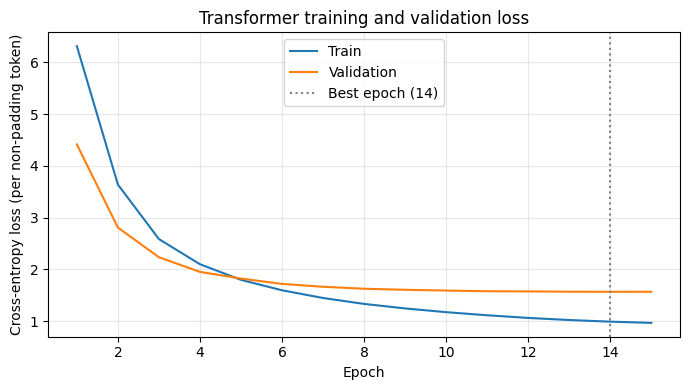

In [8]:
# Training summary and loss curves; perplexity = exp(mean validation loss)
best_val_ppl = math.exp(best_val_loss)
print("=" * 50)
print(f"Device              : {device}" + (f" ({torch.cuda.get_device_name(0)})" if device.type == 'cuda' else ""))
print(f"Seed                : {SEED}")
print(f"Model               : {N_LAYERS} enc + {N_LAYERS} dec layers, d_model={D_MODEL}, heads={N_HEADS}, "
      f"d_ff={D_FF}, dropout={DROPOUT}, post-norm")
print(f"Optimizer           : AdamW, peak lr={LR} (linear warm-up {WARMUP_STEPS} steps, then linear decay), "
      f"weight_decay={WEIGHT_DECAY}, grad clip={CLIP}")
print(f"Batch size (train)  : {train_loader.batch_size}")
print(f"Trainable params    : {n_params:,}")
print(f"Completed epochs    : {completed}")
print(f"Training time       : {train_time:.1f} s ({train_time/60:.2f} min)")
print(f"Best val loss       : {best_val_loss:.4f} (epoch {best_epoch}), saved to {CKPT_PATH}")
print(f"Validation perplexity (best model) = exp(mean val loss): {best_val_ppl:.3f}")

epochs_range = range(1, completed + 1)
plt.figure(figsize=(7, 4))
plt.plot(epochs_range, history["train_loss"], label="Train")
plt.plot(epochs_range, history["val_loss"], label="Validation")
plt.axvline(best_epoch, color="gray", linestyle=":", label=f"Best epoch ({best_epoch})")
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss (per non-padding token)")
plt.title("Transformer training and validation loss")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("transformer_loss_curves.png", dpi=150)
plt.show()

## Decoding and evaluation

In [9]:
# Load the best checkpoint into a fresh model for decoding
import subprocess, sys, importlib.util, time
if importlib.util.find_spec("sacrebleu") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "sacrebleu"])
import sacrebleu
from sacrebleu.metrics import BLEU
import torch
import torch.nn.functional as F

CKPT_PATH = "transformer_best.pt"
ckpt = torch.load(CKPT_PATH, map_location=device)
best_model = Transformer(ckpt["src_vocab"], ckpt["tgt_vocab"]).to(device)
best_model.load_state_dict(ckpt["model_state"])
best_model.eval()
print(f"Loaded {CKPT_PATH}: epoch {ckpt['epoch']}, val loss {ckpt['val_loss']:.4f}")

MAX_LEN = 64
BEAM_WIDTH = 3
ALPHA = 0.6

Loaded transformer_best.pt: epoch 14, val loss 1.5693


In [10]:
@torch.no_grad()
# Decoding functions
def greedy_decode(model, src, max_len=MAX_LEN):
    """Batched greedy decoding. Returns token ids [B, T] without BOS, padded after EOS."""
    B = src.size(0)
    src_mask = make_src_mask(src)
    # encode the source once
    memory = model.encode(src, src_mask)
    ys = torch.full((B, 1), BOS_ID, dtype=torch.long, device=src.device)
    finished = torch.zeros(B, dtype=torch.bool, device=src.device)
    for _ in range(max_len):
        logits = model.decode(ys, memory, make_tgt_mask(ys), src_mask)[:, -1]
        # never generate PAD or BOS
        logits[:, PAD_ID] = float("-inf")
        logits[:, BOS_ID] = float("-inf")
        next_tok = logits.argmax(dim=-1)
        # finished sentences are not extended
        next_tok = next_tok.masked_fill(finished, PAD_ID)
        ys = torch.cat([ys, next_tok.unsqueeze(1)], dim=1)
        finished = finished | (next_tok == EOS_ID)
        if finished.all():
            break
    return ys[:, 1:]


@torch.no_grad()
def beam_search(model, src, beam=BEAM_WIDTH, max_len=MAX_LEN, alpha=ALPHA):
    """Batched beam search. Beams are ranked by sum(log p) / L**alpha.
    Finished beams are frozen (PAD only, score unchanged) so they are never extended."""
    B, K = src.size(0), beam
    dev = src.device
    src_mask = make_src_mask(src)
    memory = model.encode(src, src_mask)
    # one copy of the encoder output per beam
    memory = memory.repeat_interleave(K, dim=0)
    src_mask_k = src_mask.repeat_interleave(K, dim=0)

    ys = torch.full((B * K, 1), BOS_ID, dtype=torch.long, device=dev)
    sum_lp = torch.zeros(B, K, device=dev)
    # at the start only the first beam is alive
    sum_lp[:, 1:] = float("-inf")
    lengths = torch.zeros(B, K, device=dev)
    finished = torch.zeros(B, K, dtype=torch.bool, device=dev)
    V = None

    for _ in range(max_len):
        logits = model.decode(ys, memory, make_tgt_mask(ys), src_mask_k)[:, -1]
        V = logits.size(-1)
        logp = F.log_softmax(logits.float(), dim=-1)
        logp[:, PAD_ID] = float("-inf")
        logp[:, BOS_ID] = float("-inf")
        logp = logp.view(B, K, V)

        fin = finished.unsqueeze(-1)
        # a finished beam can only continue with PAD at log-prob 0
        frozen = torch.full_like(logp, float("-inf"))
        frozen[:, :, PAD_ID] = 0.0
        logp = torch.where(fin, frozen, logp)

        cand_sum = sum_lp.unsqueeze(-1) + logp
        new_len = lengths.unsqueeze(-1) + (~fin).float()
        cand_score = cand_sum / new_len.clamp(min=1.0).pow(alpha)

        # keep the best K candidates per sentence
        top_score, top_idx = cand_score.view(B, K * V).topk(K, dim=-1)
        beam_idx = top_idx // V
        tok_idx = top_idx % V

        sum_lp = cand_sum.view(B, K * V).gather(1, top_idx)
        lengths = new_len.expand(B, K, V).reshape(B, K * V).gather(1, top_idx)
        finished = finished.gather(1, beam_idx) | (tok_idx == EOS_ID)

        flat_beam = (beam_idx + torch.arange(B, device=dev).unsqueeze(1) * K).reshape(-1)
        # reorder beams and append the new tokens
        ys = torch.cat([ys[flat_beam], tok_idx.reshape(-1, 1)], dim=1)

        if finished.all():
            break

    final = sum_lp / lengths.clamp(min=1.0).pow(alpha)
    best = final.argmax(dim=-1)
    out = ys.view(B, K, -1)[torch.arange(B, device=dev), best]
    return out[:, 1:]


def ids_to_text(row):
    """Stop at EOS, drop BOS/PAD, then decode with the English tokenizer."""
    ids = []
    for t in row.tolist():
        if t == EOS_ID:
            break
        if t in (PAD_ID, BOS_ID):
            continue
        ids.append(t)
    return tgt_tokenizer.decode(ids)

In [11]:
# Translate the test set with both methods; only generation is timed
def translate_test_set(decode_fn):
    """Returns (list of hypotheses, list of references, list of sources, list of ids, seconds)."""
    outputs, refs, srcs, order = [], [], [], []
    if device.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    for batch in test_loader:
        src = batch["src"].to(device)
        out = decode_fn(best_model, src).cpu()
        outputs.append(out)
        refs += batch["tgt_text"]
        srcs += batch["src_text"]
        order += batch["ids"]
    if device.type == "cuda":
        torch.cuda.synchronize()
    seconds = time.perf_counter() - start
    hyps = [ids_to_text(row) for out in outputs for row in out]
    return hyps, refs, srcs, order, seconds

# untimed warm-up so GPU start-up cost does not fall on the first method
_warm = next(iter(test_loader))["src"].to(device)
_ = greedy_decode(best_model, _warm); _ = beam_search(best_model, _warm)
if device.type == "cuda":
    torch.cuda.synchronize()

greedy_hyps, refs, srcs, order, greedy_time = translate_test_set(greedy_decode)
beam_hyps, refs_b, _, order_b, beam_time = translate_test_set(beam_search)

assert order == order_b == list(range(1000)) and refs == refs_b, "order of test sentences changed"
print(f"Greedy : {len(greedy_hyps)} translations in {greedy_time:.2f} s")
print(f"Beam {BEAM_WIDTH} : {len(beam_hyps)} translations in {beam_time:.2f} s")

Greedy : 1000 translations in 2.01 s
Beam 3 : 1000 translations in 2.66 s


In [12]:
# Corpus-level BLEU with SacreBLEU (13a tokenizer, case-sensitive, exp smoothing)
bleu_metric = BLEU(tokenize="13a", lowercase=False, smooth_method="exp")
greedy_bleu = bleu_metric.corpus_score(greedy_hyps, [refs])
beam_bleu = bleu_metric.corpus_score(beam_hyps, [refs])
signature = str(bleu_metric.get_signature())

print("SacreBLEU settings string:", signature)
print(f"Greedy BLEU : {greedy_bleu.score:.2f}   ({greedy_bleu})")
print(f"Beam   BLEU : {beam_bleu.score:.2f}   ({beam_bleu})")

SacreBLEU settings string: nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|version:2.6.0
Greedy BLEU : 49.33   (BLEU = 49.33 75.4/55.6/42.8/33.2 (BP = 0.998 ratio = 0.998 hyp_len = 12935 ref_len = 12955))
Beam   BLEU : 50.31   (BLEU = 50.31 76.1/56.7/43.8/34.3 (BP = 0.997 ratio = 0.997 hyp_len = 12912 ref_len = 12955))


In [13]:
# Comparison table
print(f"{'Method':<14}{'Beam width':>11}{'BLEU':>9}{'Total time (s)':>17}")
print(f"{'Greedy':<14}{1:>11}{greedy_bleu.score:>9.2f}{greedy_time:>17.2f}")
print(f"{'Beam search':<14}{BEAM_WIDTH:>11}{beam_bleu.score:>9.2f}{beam_time:>17.2f}")
print(f"\nBeam search took {beam_time / greedy_time:.2f}x the time of greedy decoding.")
print("Same saved model, same hardware, batch size", test_loader.batch_size, "and max length", MAX_LEN)

Method         Beam width     BLEU   Total time (s)
Greedy                  1    49.33             2.01
Beam search             3    50.31             2.66

Beam search took 1.32x the time of greedy decoding.
Same saved model, same hardware, batch size 64 and max length 64


In [14]:
# First ten test examples
for i in range(10):
    print(f"[{i}] French    : {srcs[i]}")
    print(f"    Reference : {refs[i]}")
    print(f"    Greedy    : {greedy_hyps[i]}")
    print(f"    Beam ({BEAM_WIDTH})  : {beam_hyps[i]}\n")

[0] French    : Un homme avec un chapeau orange regardant quelque chose.
    Reference : A man in an orange hat starring at something.
    Greedy    : A man in an orange hat looking at something.
    Beam (3)  : A man in an orange hat looking at something.

[1] French    : Un terrier de Boston court sur l'herbe verdoyante devant une clôture blanche.
    Reference : A Boston Terrier is running on lush green grass in front of a white fence.
    Greedy    : A Blue Riiberry dog runs on the green grass in front of a white fence.
    Beam (3)  : A Bostriped terminal in the green grass in front of a white fence.

[2] French    : Une fille en tenue de karaté brisant un bâton avec un coup de pied.
    Reference : A girl in karate uniform breaking a stick with a front kick.
    Greedy    : A girl in a bath outfit reading a stick with a kick.
    Beam (3)  : A girl in a bath outfit reading a stick with a kick.

[3] French    : Cinq personnes avec des vestes d'hiver et des casques sont debout dans

In [15]:
# Sentences where greedy and beam search disagree
diff = [i for i in range(len(refs)) if greedy_hyps[i] != beam_hyps[i]]
print(f"Greedy and beam outputs differ on {len(diff)} of {len(refs)} sentences.\n")
for i in diff[:8]:
    print(f"[{i}] French    : {srcs[i]}")
    print(f"    Reference : {refs[i]}")
    print(f"    Greedy    : {greedy_hyps[i]}")
    print(f"    Beam      : {beam_hyps[i]}\n")

Greedy and beam outputs differ on 383 of 1000 sentences.

[1] French    : Un terrier de Boston court sur l'herbe verdoyante devant une clôture blanche.
    Reference : A Boston Terrier is running on lush green grass in front of a white fence.
    Greedy    : A Blue Riiberry dog runs on the green grass in front of a white fence.
    Beam      : A Bostriped terminal in the green grass in front of a white fence.

[3] French    : Cinq personnes avec des vestes d'hiver et des casques sont debout dans la neige, avec des motoneiges en arrière-plan.
    Reference : Five people wearing winter jackets and helmets stand in the snow, with snowmobiles in the background.
    Greedy    : Five people in winter jackets and helmets are standing in the snow, with snow-covered snow-covered mountain in the background.
    Beam      : Five people in winter jackets and helmets are standing in the snow, with snow words in the background.

[5] French    : Un homme en tenue claire photographie un groupe d'homme